In [4]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph , START, END
from langgraph.graph.message import add_messages

In [5]:
class state(TypedDict):
    # here we define the state of the chatbot, which includes the messages exchanged between the user and the bot
    messages: Annotated[list, add_messages]



In [6]:
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()  



model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [7]:
def chatbot(state: state) -> state:
    return {"messages" : [model.invoke(state["messages"])]}

In [8]:

graph_builder = StateGraph(state)

# Add the chatbot node to the graph
graph_builder.add_node("chatbot", chatbot)

# Add edges to connect the chatbot node to the start and end nodes
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()

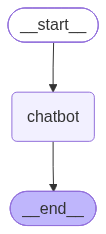

In [9]:
# visualize the graph
from IPython.display import display, Image


try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization failed:", e)

In [10]:
response = graph.invoke({"messages": "Hello, how are you?"})
print(response)  # This will print the response from the chatbot

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


{'messages': [HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='a4962e89-7bcf-4072-b92e-e678d1eb4dd2'), AIMessage(content=[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How can I help you today?", 'extras': {'signature': 'EmAKXgFpFH0TuWgBnDT4GUoDq2Jogg6ek2yjqiiUZS0bpIuX1euC+jN6pSGnF8iBnjZ3M/6K4mFiLCWTDXZDGLjbskyGdI925wZdS4aRvtQb+JRSzXTQtsu7UBSaAiK8u4o='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a15875-1430-7961-9363-be34df69ed70-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 7, 'output_tokens': 20, 'total_tokens': 27, 'input_token_details': {'cache_read': 0}})]}


In [11]:
print(response["messages"][-1]) # This will print the last message in the response

content=[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How can I help you today?", 'extras': {'signature': 'EmAKXgFpFH0TuWgBnDT4GUoDq2Jogg6ek2yjqiiUZS0bpIuX1euC+jN6pSGnF8iBnjZ3M/6K4mFiLCWTDXZDGLjbskyGdI925wZdS4aRvtQb+JRSzXTQtsu7UBSaAiK8u4o='}}] additional_kwargs={} response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'} id='lc_run--01a15875-1430-7961-9363-be34df69ed70-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 7, 'output_tokens': 20, 'total_tokens': 27, 'input_token_details': {'cache_read': 0}}


In [12]:
print(response["messages"][-1].content)  # This will print the content of the last message in the response

[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How can I help you today?", 'extras': {'signature': 'EmAKXgFpFH0TuWgBnDT4GUoDq2Jogg6ek2yjqiiUZS0bpIuX1euC+jN6pSGnF8iBnjZ3M/6K4mFiLCWTDXZDGLjbskyGdI925wZdS4aRvtQb+JRSzXTQtsu7UBSaAiK8u4o='}}]


<br><<br>>

# Tool Calling in LangChain and LangGraph

Tool calling allows an LLM to request the execution of external functions or tools to complete a task. The LLM decides which tool to use and provides its arguments, while the application executes the tool and returns the result to the LLM.

---

## 1. How Tool Calling Works

The basic flow is:

1. The user sends a message to the chatbot.
2. The message and available tools are passed to the LLM.
3. The LLM decides whether to call a tool.
4. If a tool is needed, the LLM generates a tool call with arguments.
5. `ToolNode` executes the requested tool.
6. The tool result is added to the conversation state.
7. The LLM processes the result and generates a final response.
8. The graph reaches `END` when the workflow finishes.

![LangGraph tool calling flow](images/toolinhchatbot.png)

---

## 2. What Is a Tool?

A tool is a Python function that an LLM can request to perform a specific task.

Examples:

- Calculator: Performs mathematical calculations.
- Weather API: Retrieves weather information.
- Database tool: Queries stored data.
- Search tool: Searches external information.
- Custom tool: Performs a task defined by the developer.

**Important:** The LLM normally requests a tool call; your application or agent runtime executes it. The LLM does not automatically execute arbitrary Python code.

---

## 3. Creating a Custom Tool

In LangChain, `@tool` converts a Python function into a tool that can be provided to an LLM.

```python
from langchain.tools import tool

@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the result."""
    return a * b
```

**Where**

- `@tool` = Converts the function into a LangChain tool.
- `multiply` = Tool name.
- `a` and `b` = Input arguments.
- `int` = Expected argument and return types.
- Docstring = Describes what the tool does.

**Why use?**

- Makes Python functions available to compatible LLMs.
- Provides a schema for tool arguments.
- Helps the LLM understand when the tool is appropriate.

---

## 4. Why Is the Docstring Important?

The docstring describes the purpose of a tool. The LLM can use this description to decide whether the tool matches the user's request.

```python
@tool
def get_weather(city: str) -> str:
    """Get the current weather for a specified city."""
    return f"Weather information for {city}"
```

For example:

- User: "What is the weather in Lahore?"
- The LLM may select `get_weather`.
- It supplies `city="Lahore"`.
- The tool executes and returns its result.

**Best practices**

- Use a clear and specific docstring.
- Describe exactly what the tool does.
- Use meaningful parameter names and type hints.
- Explain units, constraints, or required inputs when necessary.

**Important:** The docstring helps guide tool selection, but it does not guarantee that the LLM will always choose correctly. The tool's input schema and validation also matter.

---

## 5. Binding Tools to an LLM

Tools must be provided to a tool-capable model before it can request them.

```python
from langchain.tools import tool
from langchain_ollama import ChatOllama

@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers."""
    return a * b

llm = ChatOllama(model="qwen3.5:9b")

llm_with_tools = llm.bind_tools([multiply])
```

**Why use `bind_tools()`?**

- Makes tool definitions available to the model.
- Allows the model to return structured tool-call requests.
- Does not, by itself, execute the requested functions.

Tool-calling support depends on the selected model and its integration.

---

## 6. Understanding Tool Calls

When the LLM decides to use a tool, its response contains a tool-call request rather than only ordinary text.

Conceptually, a tool call looks like this:

```python
{
    "name": "multiply",
    "args": {
        "a": 4,
        "b": 5
    }
}
```

The model requests `multiply(4, 5)`. The application executes the function and receives `20`.

A model can also respond directly without requesting any tool.

---

## 7. What Is ToolNode?

`ToolNode` is a LangGraph component that executes tool calls found in an AI message.

It can handle one or multiple requested tool calls, subject to the tools and execution configuration.

**Main responsibilities**

- Identifies the requested tools.
- Passes arguments to the corresponding functions.
- Executes the tool calls.
- Produces tool results as messages.
- Supports handling tool execution errors when configured.

`ToolNode` does not decide the overall workflow by itself. Graph edges determine what happens next.

---

## 8. Complete Tool-Calling Graph

A common LangGraph pattern uses an LLM node, a conditional edge, and a `ToolNode`.

![LangGraph chatbot to ToolNode to END](images/2.png)

The flow is:

- `START` → The graph begins.
- `chatbot` → The LLM processes the messages and may request tools.
- `tools_condition` → Checks whether the AI message contains tool calls.
- `ToolNode` → Executes the requested tools.
- `chatbot` → Receives the tool results and decides what to do next.
- `END` → Reached when the LLM produces a response without further tool calls.

If the LLM requests another tool after receiving a result, the graph can loop through the tool-execution cycle again.

---

## 9. Conditional Routing with `tools_condition`

`tools_condition` is a helper that routes execution based on whether the latest AI message contains tool calls.

Conceptually:

- Tool calls present → Route to the tools node.
- No tool calls → Route to `END`.

This is useful because the LLM may need several rounds of tool execution before it can answer the user.

---



## 10. External Tools and APIs

A tool does not have to perform its task locally. It can call an external service.

Examples:

- Weather API
- Web search API
- Database service
- Email service
- Payment or CRM API

```python
@tool
def search_database(query: str) -> str:
    """Search the application database for matching records."""
    # Add database query logic here.
    return "Matching records"
```

The function's implementation connects to the actual database or service.

**Important:** Add authentication, input validation, error handling, and permission checks where required. Do not expose API keys in prompts or tool descriptions.

---


<br>

In [13]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results = 2)
tool.invoke("what is computer vision?")

{'query': 'what is computer vision?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.databricks.com/blog/what-is-computer-vision',
   'title': 'What is Computer Vision? | Databricks',
   'content': 'Computer vision is a field of study within computer science that focuses on enabling machines to analyze and understand visual information as closely as possible to the way humans do through the power of sight. At its core, computer vision is about generating meaningful insights from raw images or video so that technology systems can recognize objects, detect patterns and make decisions based on visual input. [...] By improving safety and reducing risk, computer vision is an important part of scalable, intelligent security and surveillance solutions that protect assets, employees and customers while optimizing resource allocation.\n\n### Agriculture and environmental monitoring [...] ## Conclusion\n\nComputer vision is poised to transform a n

In [14]:
def multiply(a: int, b: int) -> int:
    """Multiplies two integers.
    Args:
        a: The first integer.
        b: The second integer.
    Returns:
        The product of a and b.
    """
    return a * b

In [15]:
tools = [tool, multiply]

In [16]:
model_bind_tool = model.bind_tools(tools)

In [17]:
model_bind_tool

_ChatModelBinding(bound=ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-google-genai': '4.4.0'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x000002962A9C6710>, default

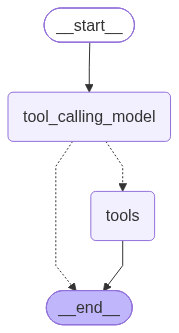

In [38]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


## node defiinition
def chatbot_with_tools(state: state) -> state:
    return {"messages" : [model_bind_tool.invoke(state["messages"])]}


## graph
builder = StateGraph(state)
builder.add_node("tool_calling_model",chatbot_with_tools)
builder.add_node("tools",ToolNode(tools))

# Add edges to connect the nodes
builder.add_edge(START, "tool_calling_model")
builder.add_conditional_edges(
    "tool_calling_model",
    # if the model decides to call a tool, go to the tools node
    # if the model decides not to call a tool, go to the end node

    tools_condition
)
builder.add_edge("tools", END)

# compile the graph
graph = builder.compile()

# visualize the graph
from IPython.display import Image , display
display(Image(graph.get_graph().draw_mermaid_png()))


In [19]:
graph.invoke({
    "messages": [{"role": "user", "content": "what is the news related ai latest?"}]
})

{'messages': [HumanMessage(content='what is the news related ai latest?', additional_kwargs={}, response_metadata={}, id='adb85796-ee01-4964-b410-d368e94892eb'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'tavily_search', 'arguments': '{"search_depth": "advanced", "query": "latest AI news developments", "time_range": "week", "topic": "news"}'}, '__gemini_function_call_thought_signatures__': {'call_127610': 'EmAKXgFpFH0T0ya8nwWwQSApZWnZN7WpnFrLkMLuQ83s3AKnlDymPVeKmBYnuNk3YyAyrjjFzJSAupkG2miS1P6sFkOmdnEgZmkUtmr1TSXZK0LXBrL2DPwmJtK8o0cfxis='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a15875-3bae-70b0-86c7-996a81e34deb-0', tool_calls=[{'name': 'tavily_search', 'args': {'search_depth': 'advanced', 'query': 'latest AI news developments', 'time_range': 'week', 'topic': 'news'}, 'id': 'call_127610', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metad

In [20]:
response = graph.invoke({
    "messages": [{"role": "user", "content": "What is the latest AI news?"}]
})
print(response["messages"][-1].content)

{"query": "latest AI news artificial intelligence updates", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://solutionsreview.com/ai-news-for-the-week-of-october-16-updates-from-digitalocean-linux-foundation-onestream-more", "title": "AI News for the Week of October 16; Updates from DigitalOcean, Linux Foundation, OneStream & More", "content": "Artificial intelligence is everywhere—but understanding its human impact has never been more urgent. That’s where _Solutions Review_‘s latest newsletter, _The Human-AI Ledger_, comes in. Designed to chronicle how AI is reshaping the way we learn, work, lead, and live, this newsletter explores the soft side of AI—the non-technical, deeply human dimensions that determine whether this technological revolution helps us thrive or leaves us behind.", "score": 0.7555112, "published_date": "Fri, 16 Oct 2026 16:44:33 GMT", "raw_content": null, "id": "6401dc-00"}, {"url": "https://www.transparencycoalition.ai/news/ai-

In [21]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the latest AI news?
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_186635)
 Call ID: call_186635
  Args:
    query: latest AI news artificial intelligence updates
    topic: news
    search_depth: basic
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news artificial intelligence updates", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://solutionsreview.com/ai-news-for-the-week-of-october-16-updates-from-digitalocean-linux-foundation-onestream-more", "title": "AI News for the Week of October 16; Updates from DigitalOcean, Linux Foundation, OneStream & More", "content": "Artificial intelligence is everywhere—but understanding its human impact has never been more urgent. That’s where _Solutions Re

In [22]:
# another tool

response = graph.invoke({
    "messages": [{"role": "user", "content": "What is 5 multiply by 5?"}]
})
print(response["messages"][-1].content)

for m in response["messages"]:
    m.pretty_print()

25
================================ Human Message =================================

What is 5 multiply by 5?
================================== Ai Message ==================================

[]
Tool Calls:
  multiply (call_158291)
 Call ID: call_158291
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: multiply

25


<br><br>

In [23]:

response = graph.invoke({
    "messages": [{"role": "user", "content": "What is the recent news related ai and 5 multiply by 10?"}]
})
print(response["messages"][-1].content)

for m in response["messages"]:
    m.pretty_print()

50
================================ Human Message =================================

What is the recent news related ai and 5 multiply by 10?
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_294947)
 Call ID: call_294947
  Args:
    query: artificial intelligence recent news 2026
    topic: news
  multiply (call_294948)
 Call ID: call_294948
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "artificial intelligence recent news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.journalofaccountancy.com/news/2026/oct/aicpa-partners-on-new-offering-that-assures-ai-systems-and-agents", "title": "AICPA partners on new offering that assures AI systems and agents", "content": "October 13, 2026\n\n## AI and the audit: AICPA publishes practice aid to assist auditors\n\nOctober 5, 2026\n\n## 

<br><br>

## Why Do We Call the LLM Again After `ToolNode`?

In LangGraph, after `ToolNode` executes a tool, we usually call the LLM again so it can **process the tool result and decide what to do next**.

This is the basic idea behind the **ReAct (Reason + Act) agent pattern**.

### Workflow

```text
START
  |
  v
LLM (Chatbot)
  |
  v
tools_condition
  |
  v
ToolNode (Execute Tool)
  |
  v
LLM (Process Tool Result)
  |
  v
tools_condition
  |
  +---- Tool call needed? ----> ToolNode
  |
  +---- No tool call ---------> END
```

![LangGraph ReAct agent workflow](images/toolbackllm.png)

### How It Works

1. **LLM:** Receives the user's question and decides whether a tool is needed.
2. **ToolNode:** Executes the requested tool and returns its result.
3. **LLM again:** Receives the tool result, interprets it, and decides whether another tool is required or whether it can answer the user.
4. **Conditional routing:** If another tool call is requested, execution returns to `ToolNode`. Otherwise, the graph reaches `END`.

### Example

**User:** What is 10 multiplied by 5?

- **First LLM call:** Requests the `multiply(10, 5)` tool.
- **ToolNode:** Executes the function and returns `50`.
- **Second LLM call:** Reads the result and generates the response: "10 multiplied by 5 is 50."
- **END:** The workflow finishes.

### Why Is This Called a ReAct Agent?

ReAct stands for **Reasoning and Acting**. The agent alternates between deciding what to do, executing an action, and processing the observation returned by that action.

This cycle can repeat multiple times until the LLM produces a final answer without requesting another tool.

**Key point:** `ToolNode` executes tools; it does not automatically make the LLM interpret their results. The graph must route back to the LLM for that step.

*Note: Calling the LLM again after a tool result is a common ReAct-style pattern, but not every LangGraph workflow must use it.*

## ReAct agent archiecture

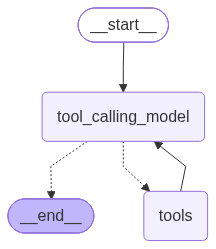

In [24]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


## node defiinition
def chatbot_with_tools(state: state) -> state:
    return {"messages" : [model_bind_tool.invoke(state["messages"])]}


## graph
builder = StateGraph(state)
builder.add_node("tool_calling_model",chatbot_with_tools)
builder.add_node("tools",ToolNode(tools))

# Add edges to connect the nodes
builder.add_edge(START, "tool_calling_model")
builder.add_conditional_edges(
    "tool_calling_model",
    # if the model decides to call a tool, go to the tools node
    # if the model decides not to call a tool, go to the end node

    tools_condition
)
builder.add_edge("tools", "tool_calling_model")

# compile the graph
graph = builder.compile()

# visualize the graph
from IPython.display import Image , display
display(Image(graph.get_graph().draw_mermaid_png()))


In [25]:

response = graph.invoke({
    "messages": [{"role": "user", "content": "What is the recent news related ai and 5 multiply by 5?"}]
})
print(response["messages"][-1].content)

for m in response["messages"]:
    m.pretty_print()

[{'type': 'text', 'text': 'Here is the information you requested:\n\n1. **5 multiplied by 5** is **25**.\n\n2. **Recent AI News:**\n   * **Model & Product Releases:** Major tech companies continue to push frontier capabilities. For instance, Google recently rolled out updates highlighted by advanced reasoning models (like Gemini 4 Argon), better natural voice tools, and tighter ecosystem integrations. Meanwhile, specialized startups like the Nvidia-backed *doubleAI* are launching new models focused on dramatically slashing compute and operational costs for businesses.\n   * **Global & Regulatory Developments:** Governments and regulatory bodies are actively managing security concerns. Notably, government bodies like the U.S. Department of Homeland Security (DHS) have issued directives regarding the restriction or removal of specific foreign-developed AI technologies (such as DeepSeek) from federal civilian IT systems.\n   * **Scientific & Startup Growth:** AI continues to make waves in

<br><br>

### Memory

In [26]:
from langchain_groq import ChatGroq
model = ChatGroq(model="qwen/qwen3.8-27b")

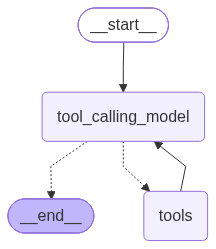

In [27]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver   # for

memory = MemorySaver()


## node defiinition
def chatbot_with_tools(state: state) -> state:
    return {"messages" : [model_bind_tool.invoke(state["messages"])]}


## graph
builder = StateGraph(state)
builder.add_node("tool_calling_model",chatbot_with_tools)
builder.add_node("tools",ToolNode(tools))

# Add edges to connect the nodes
builder.add_edge(START, "tool_calling_model")
builder.add_conditional_edges(
    "tool_calling_model",
    # if the model decides to call a tool, go to the tools node
    # if the model decides not to call a tool, go to the end node

    tools_condition
)
builder.add_edge("tools", "tool_calling_model")

# compile the graph
graph = builder.compile(checkpointer=memory)

# visualize the graph
from IPython.display import Image , display
display(Image(graph.get_graph().draw_mermaid_png()))


In [28]:
config = {"configurable":{"thread_id":"2"}}

response = graph.invoke({"messages":"hi my name is saim"}, config=config)

response["messages"]

[HumanMessage(content='hi my name is saim', additional_kwargs={}, response_metadata={}, id='36ce9591-a48e-43ee-9fca-c6997392c916'),
 AIMessage(content=[{'type': 'text', 'text': 'Hi Saim! Nice to meet you. How can I help you today?', 'extras': {'signature': 'EmAKXgFpFH0TD02iZQJegTY9CWDIFI+7jhGbd6MJoRBMqS0KPMRPM9dUP8A+cw8hig8Bm5IOZ9zAxD6Wo7gSwc/WJpRnKRkWEufs/GiqSxrpgLjW7WMoMNHKC/kIEJFZSfA='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a15875-b85b-7e51-831c-e682910f61de-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1581, 'output_tokens': 16, 'total_tokens': 1597, 'input_token_details': {'cache_read': 0}})]

In [29]:
print(response["messages"][-1].content)

[{'type': 'text', 'text': 'Hi Saim! Nice to meet you. How can I help you today?', 'extras': {'signature': 'EmAKXgFpFH0TD02iZQJegTY9CWDIFI+7jhGbd6MJoRBMqS0KPMRPM9dUP8A+cw8hig8Bm5IOZ9zAxD6Wo7gSwc/WJpRnKRkWEufs/GiqSxrpgLjW7WMoMNHKC/kIEJFZSfA='}}]


In [30]:
response = graph.invoke({"messages":"What is my name?"}, config=config)

print(response["messages"][-1].content)

[{'type': 'text', 'text': 'Your name is Saim!', 'extras': {'signature': 'EmAKXgFpFH0TeXtpBc6fapOmpCH+jpimalW1WKmaNP83jam/0Z+eEQdDfhPYhfPrlWuI/hp5rW/oQKg3kuYtrK9CcxZQO7Olc1MEYqo6kYVTeCnmFKz+xUFFcn4j74bFgTk='}}]


<br><br>

## Streaming

In [31]:
from langgraph.checkpoint.memory import MemorySaver

In [35]:
def Superbot(state: state)-> state:
    return {"messages": [model.invoke(state["messages"])]}

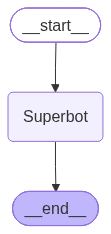

In [40]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import Image, display

graph = StateGraph(state)

# node

graph.add_node("Superbot", Superbot)

# edges
graph.add_edge(START, "Superbot")
graph.add_edge("Superbot", END)

app = graph.compile(checkpointer=MemorySaver())

# display

display(Image(app.get_graph().draw_mermaid_png()))

<br><br>

# Streaming in LangGraph

Streaming allows us to receive output progressively instead of waiting for the entire response to finish.

**Why use streaming?**
- Displays responses faster.
- Improves chatbot user experience.
- Shows intermediate workflow steps.
- Helps monitor agent and tool execution.

---

## 1. `stream()` — Synchronous Streaming

`stream()` yields output chunks progressively in a synchronous workflow.

```python
for chunk in model.stream("Explain machine learning"):
    print(chunk.content, end="", flush=True)
```

**Where**

- `model.stream()` = Generates output incrementally.
- `chunk` = A piece of the response.
- `chunk.content` = Text contained in the chunk.

**Why use?**
- Simple command-line chatbots.
- Synchronous applications.
- Processing output chunk by chunk.

---

## 2. `astream()` — Asynchronous Streaming

`astream()` is the asynchronous equivalent of `stream()`. Use `async for` to receive chunks without blocking the event loop while waiting for asynchronous operations.

```python
async for chunk in model.astream("Explain machine learning"):
    print(chunk.content, end="", flush=True)
```

The example above must run inside an `async` function.

**Why use?**
- Async web applications.
- FastAPI applications.
- Applications handling multiple concurrent requests.

**Key difference**

- `stream()` → Synchronous iteration using `for`.
- `astream()` → Asynchronous iteration using `async for`.

---

## 3. Streaming in LangGraph

LangGraph can stream more than just the LLM's text. It can expose graph state updates, individual message chunks, and node execution events.

The main streaming modes are:

| Mode | Purpose |
|---|---|
| `"updates"` | Shows state updates produced by graph nodes. |
| `"values"` | Shows the full state after each graph step. |
| `"messages"` | Streams LLM message chunks and metadata. |
| `"custom"` | Streams custom data emitted by your code. |
| `"debug"` | Provides detailed execution information for debugging. |

---

## 4. `stream_mode="updates"`

Returns state updates produced by individual nodes.

```python
for chunk in graph.stream(
    {"messages": [("user", "Hello")]},
    stream_mode="updates"
):
    print(chunk)
```

**Why use?**

- See which node executed.
- Inspect intermediate node results.
- Monitor chatbot and tool execution.

---

## 5. `stream_mode="values"`

Returns the full graph state after each step, rather than only the latest node's updates.

```python
for chunk in graph.stream(
    {"messages": [("user", "Hello")]},
    stream_mode="values"
):
    print(chunk)
```

**Difference**

- `"updates"` → Only the state changes returned by a node.
- `"values"` → The complete state after a graph step.

---

## 6. `stream_mode="messages"`

Streams LLM message chunks along with metadata, which can identify the graph node that generated them.

```python
for message_chunk, metadata in graph.stream(
    {"messages": [("user", "Explain AI")]},
    stream_mode="messages"
):
    print(message_chunk.content, end="", flush=True)
```

**Why use?**

- Display chatbot responses token by token.
- Build real-time chat interfaces.
- Identify which node generated a message.

This mode is particularly useful when a graph contains multiple LLM nodes.

---

## 7. Asynchronous Streaming in LangGraph

Use `astream()` for asynchronous graph streaming.

```python
async for chunk in graph.astream(
    {"messages": [("user", "Hello")]},
    stream_mode="updates"
):
    print(chunk)
```

You can also use `astream_events()` when you need detailed events such as model starts, model output chunks, tool execution, and chain completion.



<br>

In [44]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

graph = graph_builder.compile(checkpointer=memory)

In [47]:

# create a thread
config = {"configurable": {"thread_id": "3"}}
for chuck in graph.stream({"messages": "Hello,Tell me about machine learning?"}, config , stream_mode="updates"):
    print(chuck)

{'chatbot': {'messages': [AIMessage(content='Hello! **Machine Learning (ML)** is a fascinating subfield of Artificial Intelligence (AI) that focuses on building systems that can learn from data, identify patterns, and make decisions or predictions with minimal human intervention.\n\nHere’s a breakdown of the key concepts to help you understand it:\n\n### 1. What is Machine Learning?\nInstead of being explicitly programmed with specific rules (like traditional software), ML algorithms are fed large amounts of data and allowed to find patterns on their own. The system "learns" from examples, improving its performance over time.\n\n**Simple Analogy:**\n- **Traditional Programming:** You give the computer instructions: *"If X, then Y."*\n- **Machine Learning:** You give the computer examples: *"Here are 1,000 images of cats and dogs; now, figure out how to tell them apart."*\n\n### 2. Main Types of Machine Learning\nML is generally categorized into three main types:\n\n#### A. Supervised L

In [48]:
for chuck in graph.stream({"messages": "Hello,Tell me about machine learning?"}, config , stream_mode="values"):
    print(chuck)

# in vlaues -> it will return the final state of the graph after processing the input, which includes the messages exchanged between the user and the bot. 
# In updates -> it will return each intermediate state of the graph as it processes the input, allowing you to see how the state evolves over time.

{'messages': [HumanMessage(content='Hello,Tell me about machine learning?', additional_kwargs={}, response_metadata={}, id='ae0d2f4b-4cf7-4232-8ec0-cc0a383c4d75'), AIMessage(content='Hello! **Machine Learning (ML)** is a fascinating subfield of Artificial Intelligence (AI) that focuses on building systems that can learn from data, identify patterns, and make decisions or predictions with minimal human intervention.\n\nHere’s a breakdown of the key concepts to help you understand it:\n\n### 1. What is Machine Learning?\nInstead of being explicitly programmed with specific rules (like traditional software), ML algorithms are fed large amounts of data and allowed to find patterns on their own. The system "learns" from examples, improving its performance over time.\n\n**Simple Analogy:**\n- **Traditional Programming:** You give the computer instructions: *"If X, then Y."*\n- **Machine Learning:** You give the computer examples: *"Here are 1,000 images of cats and dogs; now, figure out how 

In [49]:
# Stream LLM response chunks token by token.
# stream_mode="messages" returns:
#   1. message_chunk: the generated message fragment
#   2. metadata: information about the graph node and model execution

for message_chunk, metadata in graph.stream(
    {"messages": "Explain deep learning in simple terms."},
    config=config,
    stream_mode="messages",
):
    # Print only text content as it is generated
    if isinstance(message_chunk.content, str):
        print(message_chunk.content, end="", flush=True)

print()  # Move to the next line after streaming is complete

Deep learning is a specialized subset of machine learning that uses **artificial neural networks** with many layers (hence "deep") to learn from data.

To explain it in simple terms, let’s use an analogy:

### 🧠 The Human Brain Analogy
Your brain has billions of tiny cells called **neurons** that are connected to each other. When you see a cat, different neurons fire in response to specific features like ears, stripes, or whiskers. Eventually, a group of neurons "lights up" and your brain says, *"That’s a cat!"*

Deep learning mimics this process:
- **Neurons** = Simple mathematical calculations.
- **Layers** = Groups of neurons.
- **Depth** = Many layers stacked on top of each other.

### How It Works (Step-by-Step)

Imagine teaching a deep learning model to recognize a **dog** in a photo:

1. **Input Layer (The Eyes):**  
   The model receives raw pixel data from the image.

2. **Early Layers (Simple Features):**  
   The first few layers learn to detect very basic things, like:
   -

<br>

In [ ]:
# Stream the LangGraph response asynchronously
async for message_chunk in graph.astream(
    {"messages": "Explain deep learning in simple terms."},
    config=config,
    stream_mode="messages",
):

    print(message_chunk)     # astream gives much more control over the streaming process, allowing you to handle each message chunk as it arrives and perform additional asynchronous operations if needed.


(AIMessageChunk(content='', additional_kwargs={}, response_metadata={'model_provider': 'groq'}, id='lc_run--01a15982-e5b4-79d1-8441-030270aa79e0', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'thread_id': '3', 'ls_integration': 'langchain_chat_model', 'langgraph_step': 10, 'langgraph_node': 'chatbot', 'langgraph_triggers': ('branch:to:chatbot',), 'langgraph_path': ('__pregel_pull', 'chatbot'), 'langgraph_checkpoint_ns': 'chatbot:7fada258-47fb-7d3d-aef2-512dc949cd2e', 'checkpoint_ns': 'chatbot:7fada258-47fb-7d3d-aef2-512dc949cd2e', 'ls_provider': 'groq', 'ls_model_name': 'qwen/qwen3.8-27b', 'ls_model_type': 'chat', 'ls_temperature': 0.7, 'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}})
(AIMessageChunk(content='Deep', additional_kwargs={}, response_metadata={'model_provider': 'groq'}, id='lc_run--01a15982-e5b4-79d1-8441-030270aa79e0', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[]), {'thread_id': '3', 'ls_integration': 'langchain_chat_model', 